In [204]:
from scipy import optimize
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math
from scipy.spatial.distance import pdist
from sympy import latex, sqrt, log, symbols, exp
from sympy import derive_by_array, solve, hessian
from sympy import lambdify

In [205]:
x1, x2 = symbols("x1 x2")

h1 = x1**2 + x2**2
h2 = x1**2
h3 = exp(x1)


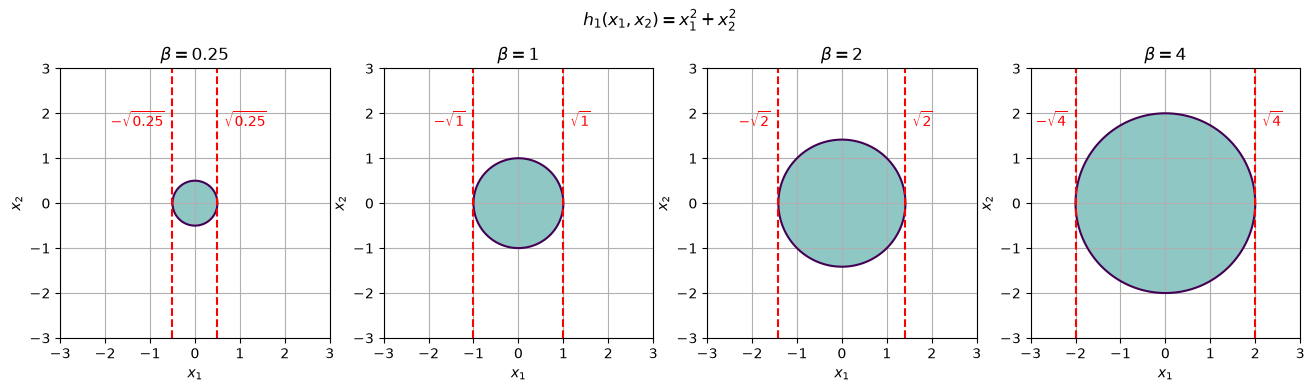

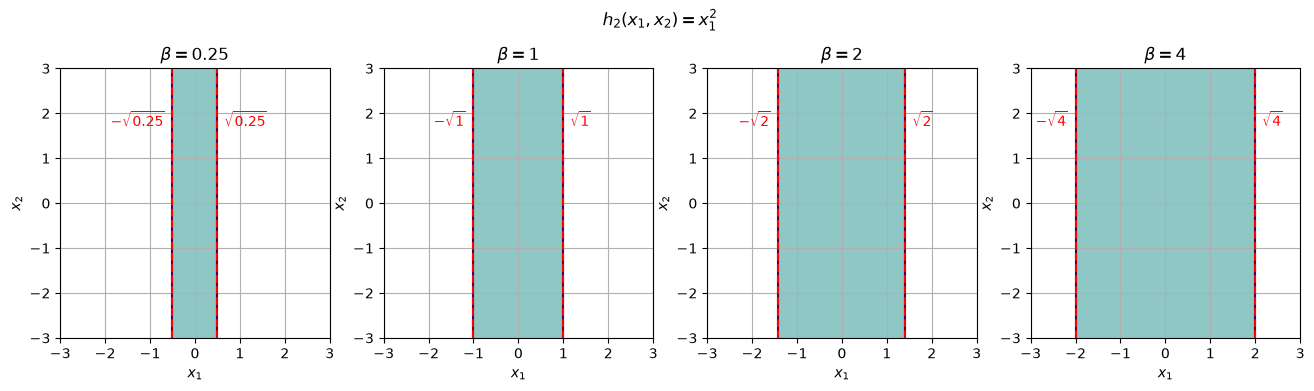

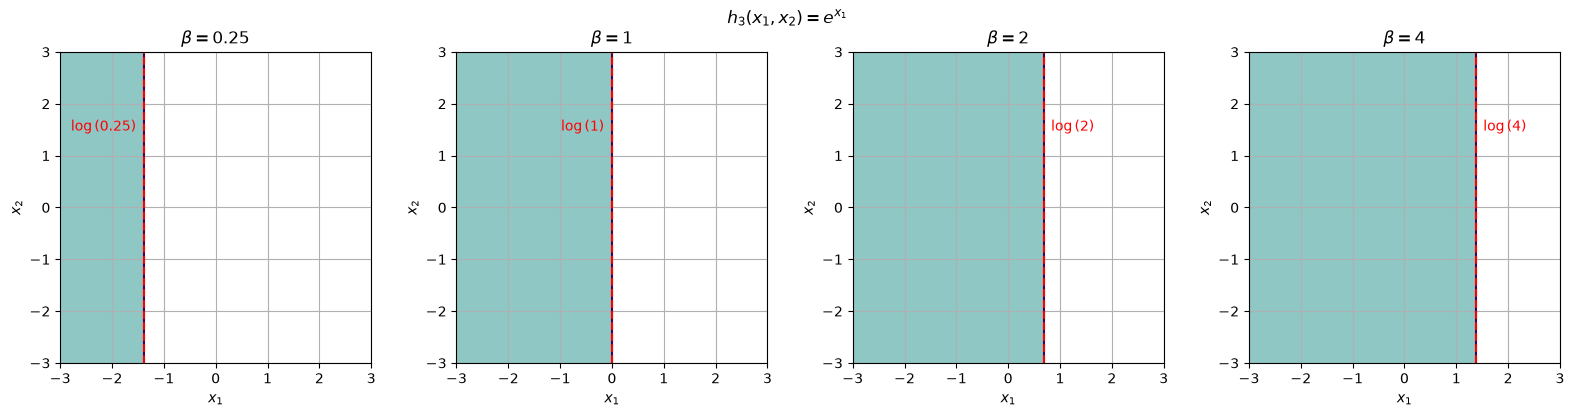

In [206]:
betas = [0.25, 1, 2, 4]
left, right = -3.0, 3.0

X2, X1 = np.mgrid[left:right:400j, left:right:400j]
funcs = [h1, h2, h3]
funcs_results = {}

for i, h in enumerate(funcs):
    title = f"$h_{i + 1}(x_1, x_2)={latex(h)}$"
    f = lambdify((x1, x2), h, "numpy")
    Z = f(X1, X2)

    fig, axes = plt.subplots(1, len(betas), figsize=(16, 4))

    for ax, beta in zip(axes, betas):
        ax.contourf(X1, X2, Z, levels=[Z.min(), beta], alpha=0.5)
        cs = ax.contour(X1, X2, Z, levels=[beta])
        points = cs.allsegs[0][0]
        funcs_results[(h, beta)] = points

        # --- теоретические границы
        if h in (h1, h2):
            lines = [-sqrt(beta, evaluate=False), sqrt(beta, evaluate=False)]
        else:
            lines = [log(beta, evaluate=False)]

        for line in lines:
            line_val = float(line)

            ax.axvline(line_val, ls="--", color="red")

            ax.annotate(
                f"${latex(line)}$",
                xy=(line_val, 0),
                xytext=(5 if line_val > 0 else -5, 55),
                textcoords="offset points",
                color="red",
                ha='left' if line_val > 0 else 'right',
            )
        # ---

        ax.set(
            title=rf"$\beta={beta}$",
            xlabel="$x_1$",
            ylabel="$x_2$",
            aspect="equal",
        )
        ax.grid()

    fig.suptitle(title)

plt.tight_layout()
plt.show()

In [212]:
diams_of_h1 = {}
for (h, beta), points in funcs_results.items():
    if h == h1:
        diameter = pdist(points).max()
        diams_of_h1[beta] = diameter
        print(f"Diameter of h1 for β={beta}: {diameter:.2f}")

Diameter of h1 for β=0.25: 1.00
Diameter of h1 for β=1: 2.00
Diameter of h1 for β=2: 2.83
Diameter of h1 for β=4: 4.00


In [214]:
theta = 1.0

for beta, diam in diams_of_h1.items():
    if diam <= 2.0 * np.sqrt(beta / theta):
        print(f"Condition satisfied for β={beta} with diameter={diam:.2f}")
    else:
        print(f"Condition NOT satisfied for β={beta} with diameter={diam:.2f}")

Condition satisfied for β=0.25 with diameter=1.00
Condition satisfied for β=1 with diameter=2.00
Condition satisfied for β=2 with diameter=2.83
Condition satisfied for β=4 with diameter=4.00


In [209]:
np.random.seed(0)
start_point = np.random.rand(2)
f1 = lambdify((x1, x2), h1, "numpy")

min_h1 = optimize.minimize(lambda X: f1(*X), start_point)

print(f"Minimum of h1: {min_h1.fun:.16f}")
print(f"Point: {min_h1.x[0]:.16f}, {min_h1.x[1]:.16f}")

Minimum of h1: 0.0000000000000001
Point: -0.0000000066317851, -0.0000000085190206


In [217]:
x1, x2 = symbols("x1 x2", real=True)
f = x1**2 + x2**2

# 1. Градиент
grad = derive_by_array(f, vars)
display(Math(f"\\nabla f= {latex(grad)}"))

# 2. Стационарные точки
point = solve(grad, vars, dict=True)
display(Math(f"\\nabla f=0:\\quad {latex(point)}"))


# 3. Гессиан
H = hessian(f, vars)
display(Math(f"H_f= {latex(H)}"))


# 4. Гессиан в стационарной точке
H0 = H.subs(point[0])
display(Math(f"H_f(x^*)= {latex(H0)}"))


# 5. Собственные значения
eigenvalues = H0.eigenvals()

display(
    Math(
        r"\lambda(H_f(x^*))="
        + r"\left\{"
        + ", ".join(latex(l) for l in eigenvalues)
        + r"\right\}"
    )
)


# 6. Проверка условия минимума
is_min = all(lam > 0 for lam in eigenvalues)

display(Math("\\lambda_i>0\\Rightarrow x^* \text{ -- min}"))

# 7. Значение функции
f_min = f.subs(point[0])

display(Math("f_{{min}}=f(x^*)=" + latex(f_min)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>